In [ ]:
# import pandas for working with tables(matrices) and csv files
import pandas as pd

# save the path of the training csv file
train_path = "../data/raw/sign_mnist_train.csv"

# save the path of the test csv file
test_path = "../data/raw/sign_mnist_test.csv"

# read the training csv file into a pandas dataframe
train_df = pd.read_csv(train_path)

# read the test csv file into a pandas dataframe
test_df = pd.read_csv(test_path)

# print the number of rows and columns in the training data
print("train shape:", train_df.shape)

# print the number of rows and columns in the test data
print("test shape:", test_df.shape)


print("\n first ten train columns:")

# print the first ten column names from the training data
print(train_df.columns[:10])


print("\nfirst 5 rows:")

# display the first five rows of the training data
display(train_df.head())

train shape: (27455, 785)
test shape: (7172, 785)

train columns:
Index(['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9'],
      dtype='str')

first rows:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [2]:
# get all unique label values from the training data and sort them
print("unique labels:", sorted(train_df["label"].unique()))

# count how many different classes exist in the training data
print("number of classes:", train_df["label"].nunique())

# print a title before showing the class distribution
print("\ntrain class distribution:")

# count how many training samples belong to each label and sort by label number
print(train_df["label"].value_counts().sort_index())

unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
number of classes: 24

train class distribution:
label
0     1126
1     1010
2     1144
3     1196
4      957
5     1204
6     1090
7     1013
8     1162
10    1114
11    1241
12    1055
13    1151
14    1196
15    1088
16    1279
17    1294
18    1199
19    1186
20    1161
21    1082
22    1225
23    1164
24    1118
Name: count, dtype: int64


In [3]:
# create a list with all columns except the label column
pixel_columns = [col for col in train_df.columns if col != "label"]

# print how many pixel columns exist
print("number of pixel columns:", len(pixel_columns))

# find and print the smallest pixel value in the training data
print("pixel min:", train_df[pixel_columns].min().min())

# find and print the largest pixel value in the training data
print("pixel max:", train_df[pixel_columns].max().max())

number of pixel columns: 784
pixel min: 0
pixel max: 255


## Initial Dataset Inspection

we can see that, the sign Language MNIST dataset, was loaded successfully.

- Training samples(pictures): 27,455
- Test samples(pictures): 7,172
- Number of pixel features in each picture vector sample: 784
- Image size: 28 × 28 pixels
- Number of classes: 24
- Pixel value range: 0–255 (0 is black, 255 is white, between is gray )
- Labels 9 and 25 are not exist, because the corresponding ASL letters
  require motion, and  therefore not represented as static hand signs and therefore we have 24 classes of letters.

## Visual Inspection of Training Images

now i will reshape each feature vector back into a real 28 × 28 grayscale image
and display several training examples, to verify that the data was loaded correctly.

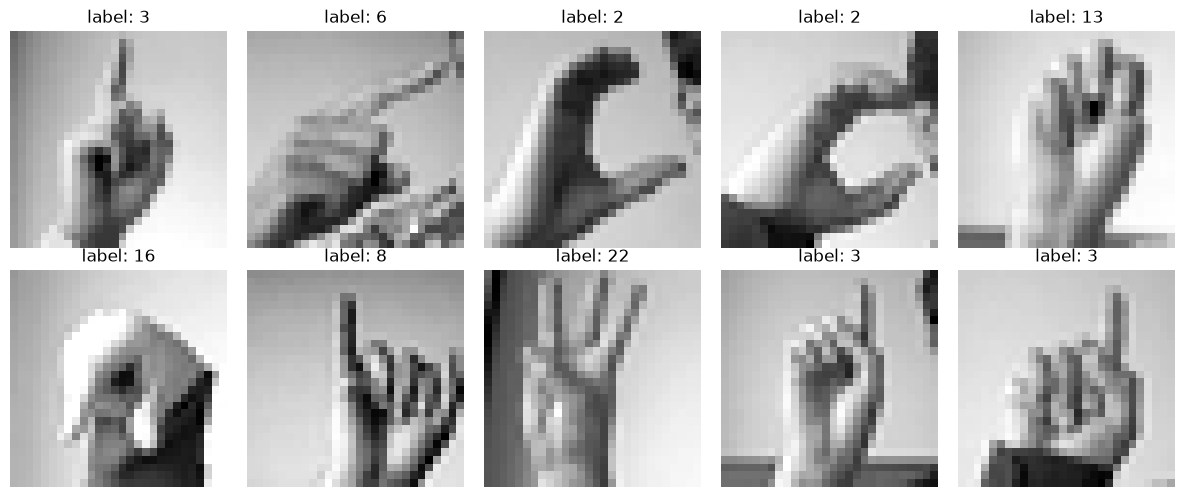

In [4]:
# import matplotlib for creating plots
import matplotlib.pyplot as plt

# create a figure with two rows and five columns
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# go through the ten plot positions
for i, ax in enumerate(axes.flat):

    # get the pixel values of the current training image
    image = train_df.iloc[i][pixel_columns].to_numpy()

    # reshape the 784 pixel values into a 28 by 28 image
    image = image.reshape(28, 28)

    # get the numeric label of the current image
    label = int(train_df.iloc[i]["label"])

    # show the image in grayscale
    ax.imshow(image, cmap="gray")

    # show the label above the image
    ax.set_title(f"label: {label}")

    # hide the x and y axes
    ax.axis("off")

# fix the spacing between the images
plt.tight_layout()

# show the figure
plt.show()

## Training Class Distribution

### Expectation

based on the class counts we inspected earlier around 1000 for each class, i expect the training set
to be relatively balanced.

i expect some differences between the number of samples in each class,
but no class should be dramatically larger or smaller than the others.

the purpose of this plot, is to visually verify the class balance before
starting the classification experiments.

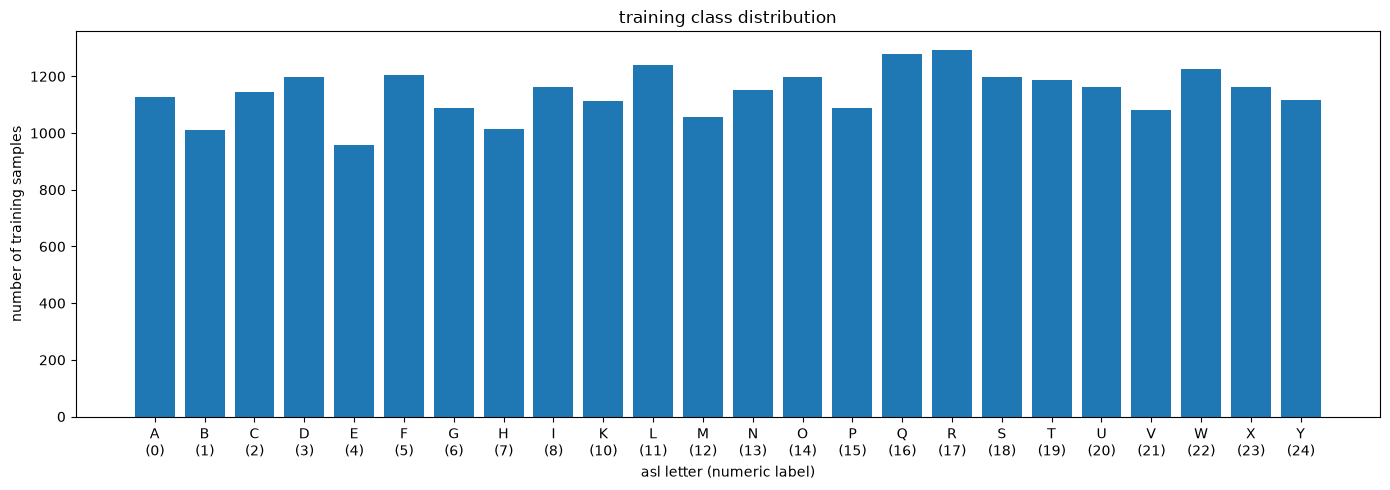

In [ ]:
# count how many training samples, belong to each label and sort by label number
class_counts = train_df["label"].value_counts().sort_index()

# get the label numbers as a list
labels = class_counts.index.to_list()

# convert each numeric label into its letter , A->0, B->1, C->2, ...
letters = [
    chr(ord("A") + int(label))
    for label in labels
]

# create labels that show both the letter and the numeric label
display_labels = [
    f"{letter}\n({label})"
    for letter, label in zip(letters, labels)
]

# create a new figure for the bar chart
plt.figure(figsize=(14, 5))

# draw one bar for each class
plt.bar(
    range(len(labels)),
    class_counts.values
)

# place the letter and numeric label under each bar
plt.xticks(
    range(len(labels)),
    display_labels
)

# write the horizontal axis name
plt.xlabel("asl letter (numeric label)")

# write the vertical axis name
plt.ylabel("number of training samples")

# write the graph title
plt.title("training class distribution")

# fix the spacing around the graph
plt.tight_layout()

# save the graph as an image file
plt.savefig(
    "../results/figures/train_class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

# show the graph
plt.show()

In [6]:
# print the label with the smallest number of samples
print(
    "smallest class:",
    class_counts.idxmin(),
    "-",
    class_counts.min(),
    "samples"
)

# print the label with the largest number of samples
print(
    "largest class:",
    class_counts.idxmax(),
    "-",
    class_counts.max(),
    "samples"
)

# calculate and print the ratio between the largest and smallest classes
print(
    "largest / smallest ratio:",
    class_counts.max() / class_counts.min()
)

smallest class: 4 - 957 samples
largest class: 17 - 1294 samples
largest / smallest ratio: 1.3521421107628004


### Result and Conclusion

the class distribution is relatively balanced.

the smallest class contains 957 training samples, while the largest
contains 1294 samples.

the largest-to-smallest class ratio is approximately 1.35.

this confirm my expectation that the dataset contains some variation
in class sizes, but no big class imbalance.

## Data Quality Checks

### Expectation

i expect the dataset to contain no missing pixel values.

i also expect the training and test sets to be separate, with no exact
duplicate samples shared between them.

i will check missing values and duplicates ,before continuing to the
preprocessing stage.

In [7]:
# Missing values
print("Missing values in train:", train_df.isna().sum().sum())
print("Missing values in test:", test_df.isna().sum().sum())

# Duplicate complete rows
print("Duplicate rows in train:", train_df.duplicated().sum())
print("Duplicate rows in test:", test_df.duplicated().sum())

Missing values in train: 0
Missing values in test: 0
Duplicate rows in train: 0
Duplicate rows in test: 0


## train-test overlap check

### expectation

i expect the train and test sets to contain different images.

if the exact same image appears in both sets, the test result may be less reliable
because the model could have already seen that image during training.

In [8]:
# create a hash for each train image
train_hashes = pd.util.hash_pandas_object(
    train_df[pixel_columns],
    index=False
)

# create a hash for each test image
test_hashes = pd.util.hash_pandas_object(
    test_df[pixel_columns],
    index=False
)

# convert train hashes to a set for faster search
train_hash_set = set(train_hashes)

# check if each test image also exists in train
shared_images = test_hashes.isin(train_hash_set)

# count shared images
shared_count = shared_images.sum()

# print the result
print("shared images between train and test:", shared_count)

shared images between train and test: 0


## preparing the data for stage 1

### expectation

i expect the training data to contain 784 features for each image.

i will split the original training data into a training set and a validation set.

the original test set will remain untouched and will only be used for final evaluation.

i will also scale the pixel values from 0-255 to 0-1 , for making it more convenience

In [9]:
from sklearn.model_selection import train_test_split

# take only the pixel columns from the training data
x_full = train_df[pixel_columns].to_numpy()

# take the labels from the training data
y_full = train_df["label"].to_numpy()

# take only the pixel columns from the test data
x_test = test_df[pixel_columns].to_numpy()

# take the labels from the test data
y_test = test_df["label"].to_numpy()

# split the original training data into train and validation
x_train, x_val, y_train, y_val = train_test_split(
    x_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

# scale the training pixels from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0

# scale the validation pixels from 0-255 to 0-1
x_val = x_val.astype("float32") / 255.0

# scale the test pixels from 0-255 to 0-1
x_test = x_test.astype("float32") / 255.0

# print the shape of the training features
print("x_train shape:", x_train.shape)

# print the shape of the validation features
print("x_val shape:", x_val.shape)

# print the shape of the test features
print("x_test shape:", x_test.shape)

# print the shape of the training labels
print("y_train shape:", y_train.shape)

# print the shape of the validation labels
print("y_val shape:", y_val.shape)

# print the shape of the test labels
print("y_test shape:", y_test.shape)

# print the smallest pixel value after scaling
print("minimum pixel value:", x_train.min())

# print the largest pixel value after scaling
print("maximum pixel value:", x_train.max())

x_train shape: (21964, 784)
x_val shape: (5491, 784)
x_test shape: (7172, 784)
y_train shape: (21964,)
y_val shape: (5491,)
y_test shape: (7172,)
minimum pixel value: 0.0
maximum pixel value: 1.0


In [10]:
# calculate the class proportions in the training set
train_distribution = pd.Series(y_train).value_counts(normalize=True).sort_index()

# calculate the class proportions in the validation set
val_distribution = pd.Series(y_val).value_counts(normalize=True).sort_index()

# put the two distributions in one table
distribution_compare = pd.DataFrame({"train": train_distribution, "validation": val_distribution})

# calculate the difference between the two proportions
distribution_compare["difference"] = abs(distribution_compare["train"] - distribution_compare["validation"])

# show the comparison table
display(distribution_compare)

# find the largest difference between train and validation
max_difference = distribution_compare["difference"].max()

# print the largest difference
print("largest proportion difference:", max_difference)

,train,validation,difference
0,0.041022,0.040976,0.000046
1,0.036787,0.036787,0.000000
2,0.041659,0.041705,0.000046
3,0.043571,0.043526,0.000046
4,0.034875,0.034784,0.000091
5,0.043844,0.043890,0.000046
6,0.039701,0.039701,0.000000
7,0.036879,0.036970,0.000091
8,0.042342,0.042251,0.000091
10,0.040566,0.040612,0.000046


largest proportion difference: 9.105809506465556e-05


### result and conclusion

the class proportions in the training and validation sets are almost identical.

(the presentage of each class in each set)

the largest difference between the two sets is more or less 0.000091.

this show me that the stratified split, successfully preserved the class distribution.

the validation set should therefore provide a fair comparison between the models.

## experiment 1: 1-nearest neighbor

### question

does the nearest image in pixel space usually belong to the same class?

### pixel-space intuition

each image is represented as a point in a 784-dimensional space.

if two images have similar pixel values, their points will be close to each other
in this space.

so, for images of the same hand sign, i expect many of them to be relatively close
to each other in pixel space.

but in my opinion, this is not always guaranteed.

the same hand sign can appear with a different hand position, angle, lighting,
or background.

because of this, two images can represent the same letter but still be far apart
in pixel space.

the main idea of this experiment is to test whether geometric closeness in pixel
space usually matches the true letter class.

### prediction

i expect 1-nearest neighbor(1-nn) to achieve good accuracy, because images of the
same hand sign should often have similar pixel patterns.

but, i do not expect perfect accuracy, because changes in hand position,
lighting, and background can create large pixel differences even when the
letter is the same.

In [11]:
# import the nearest neighbor classifier
from sklearn.neighbors import KNeighborsClassifier

# import the function that calculates accuracy
from sklearn.metrics import accuracy_score

# create a model that uses one nearest neighbor
knn_1 = KNeighborsClassifier(n_neighbors=1, metric="euclidean", n_jobs=-1)

# store the training data inside the model
knn_1.fit(x_train, y_train)

# predict the labels of the validation images
y_val_pred_knn_1 = knn_1.predict(x_val)

# calculate the validation accuracy
knn_1_accuracy = accuracy_score(y_val, y_val_pred_knn_1)

# print the validation accuracy
print("validation accuracy:", knn_1_accuracy)

validation accuracy: 0.9987251866690949


### result and conclusion

the validation accuracy is mor or less 99.87%.

that means, the model correctly classified 5484 out of 5491 validation images.

only 7 validation images were classified incorrectly.

this result strongly supports the idea that images of the same hand sign
are usually close to each other in pixel space.

however, the result is not perfect, so there are still cases where pixel
distance does not correctly represent the letter identity.

In [12]:
# import numpy
import numpy as np

# find which predictions are wrong
wrong_mask = y_val_pred_knn_1 != y_val

# count the wrong predictions
wrong_count = wrong_mask.sum()

# print the number of wrong predictions
print("wrong predictions:", wrong_count)

# get the positions of the wrong predictions
wrong_indices = np.where(wrong_mask)[0]

# print the positions of the wrong predictions
print("wrong indices:", wrong_indices)

wrong predictions: 7
wrong indices: [ 296  359  681  988 1655 3857 4977]


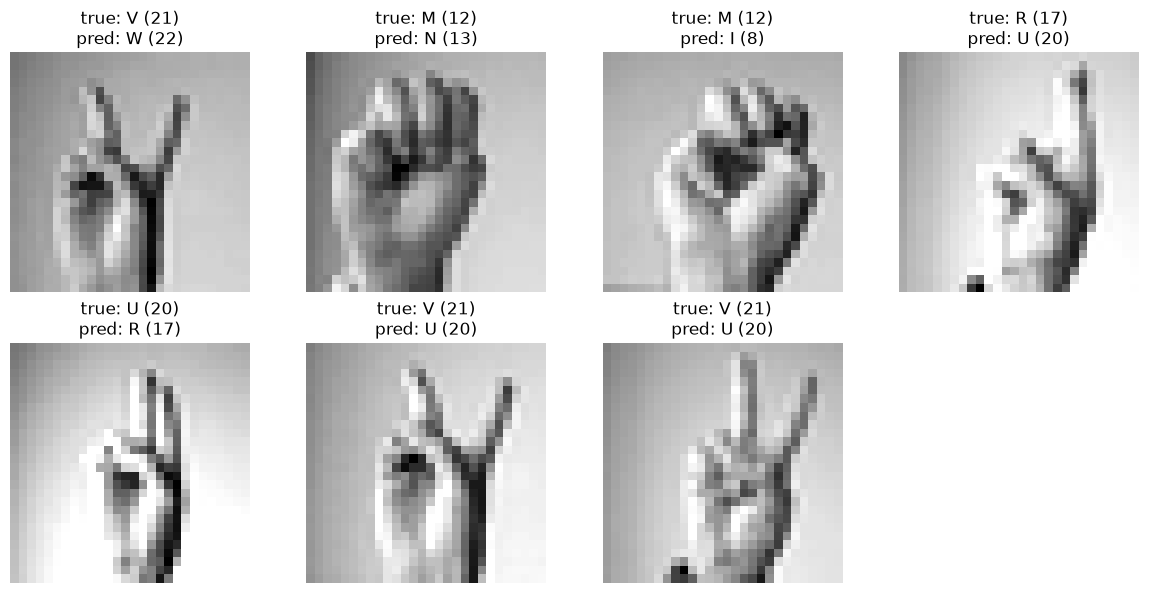

In [13]:
# create a figure with two rows and four columns
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# go through the seven wrong predictions
for ax, index in zip(axes.flat, wrong_indices):

    # reshape the image back to 28 by 28 pixels
    image = x_val[index].reshape(28, 28)

    # get the true numeric label
    true_label = int(y_val[index])

    # get the predicted numeric label
    predicted_label = int(y_val_pred_knn_1[index])

    # convert the true label to a letter
    true_letter = chr(ord("A") + true_label)

    # convert the predicted label to a letter
    predicted_letter = chr(ord("A") + predicted_label)

    # show the image
    ax.imshow(image, cmap="gray")

    # show the true and predicted labels
    ax.set_title(
        f"true: {true_letter} ({true_label})\npred: {predicted_letter} ({predicted_label})"
    )

    # hide the axes
    ax.axis("off")

# hide the unused last plot
axes.flat[-1].axis("off")

# fix the spacing between the plots
plt.tight_layout()

# show the figure
plt.show()

### error analysis

the 1-nearest neighbor model made only 7 mistakes.

we can see that the most of the mistakes happened between hand signs that have similar shapes.

for example, the model confused v with w and u, and it also confused
r with u.

this tell me that pixel-space distance works very well for this dataset,
but it can fail when different letters have visually similar hand shapes.

the result support the idea that geometric closeness in pixel space is
often related to letter identity, but the relationship is not perfect.

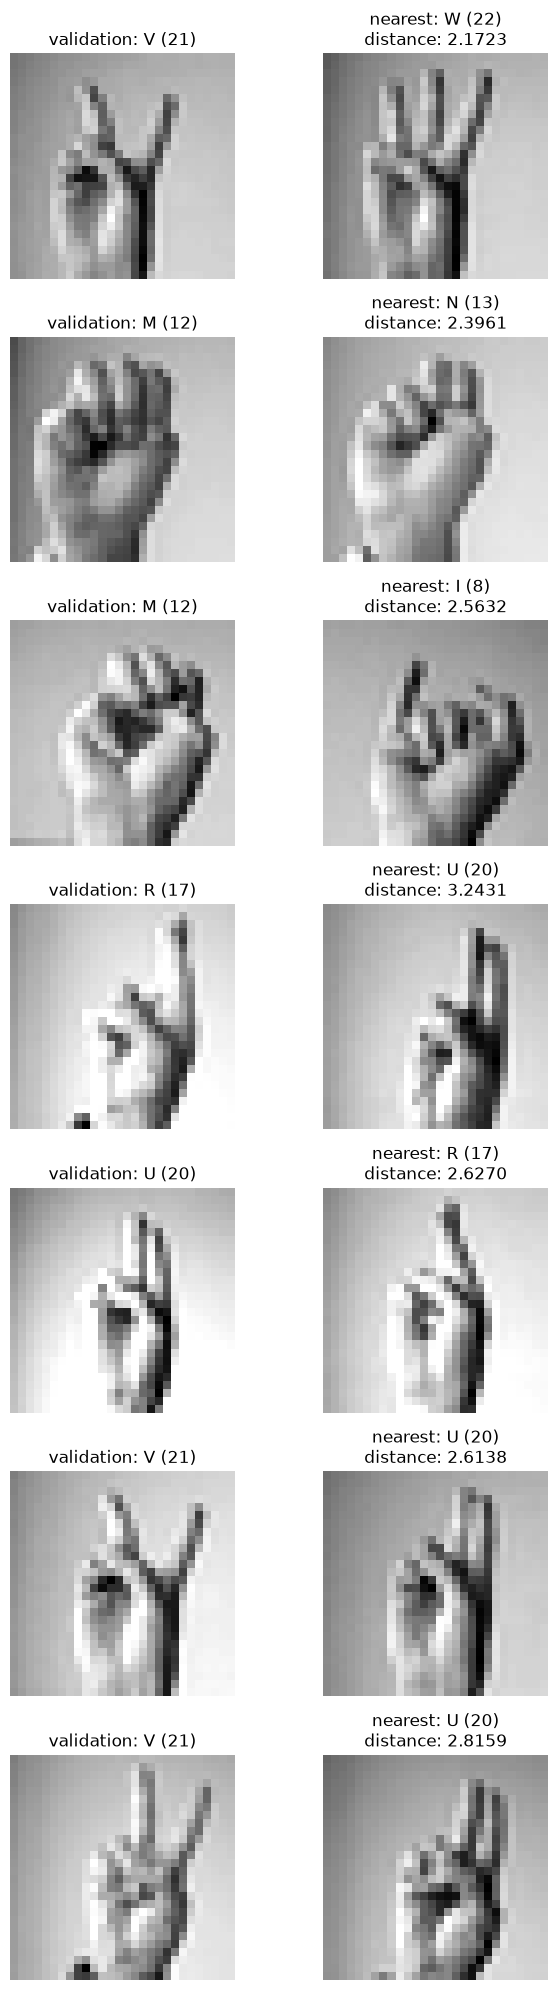

In [14]:
# find the nearest training image for every wrong validation image
distances, neighbor_indices = knn_1.kneighbors(
    x_val[wrong_indices],
    n_neighbors=1,
    return_distance=True
)

# create a figure for the wrong images and their nearest neighbors
fig, axes = plt.subplots(len(wrong_indices), 2, figsize=(7, 20))

# go through every wrong validation image
for row, val_index in enumerate(wrong_indices):

    # get the nearest training image index
    train_index = neighbor_indices[row, 0]

    # get the distance to the nearest training image
    distance = distances[row, 0]

    # reshape the validation image
    val_image = x_val[val_index].reshape(28, 28)

    # reshape the nearest training image
    train_image = x_train[train_index].reshape(28, 28)

    # get the true validation label
    true_label = int(y_val[val_index])

    # get the nearest training label
    neighbor_label = int(y_train[train_index])

    # convert the true label to a letter
    true_letter = chr(ord("A") + true_label)

    # convert the neighbor label to a letter
    neighbor_letter = chr(ord("A") + neighbor_label)

    # show the validation image
    axes[row, 0].imshow(val_image, cmap="gray")

    # show the true label
    axes[row, 0].set_title(f"validation: {true_letter} ({true_label})")

    # hide the validation axes
    axes[row, 0].axis("off")

    # show the nearest training image
    axes[row, 1].imshow(train_image, cmap="gray")

    # show the neighbor label and distance
    axes[row, 1].set_title(
        f"nearest: {neighbor_letter} ({neighbor_label})\ndistance: {distance:.4f}"
    )

    # hide the training axes
    axes[row, 1].axis("off")

# fix the spacing
plt.tight_layout()

# show the figure
plt.show()

### nearest-neighbor error inspection

for each 7 wrong predictions, i compared the validation image with its nearest
training image.

the image pairs are visually similar in many cases.

for example, v was confused with w and u, while r and u were also confused
with each other.

this shows why pixel distance can work very well but still make mistakes.

the classifier only compares the 784 pixel values. it does not understand
the meaning of the hand shape.

small differences in finger position can represent different letters even
when the overall images are very close in pixel space.

## experiment 2: different values of k

### question

does using more than one nearest neighbor improve the validation accuracy?

### prediction

i expect a small value of k, such as 3 or 5, to perform well even better the k=1.

because ,using several neighbors may reduce mistakes caused by one unusual nearest image.

but in my opinion, if k becomes too large, images from other classes may influence
the prediction and reduce the accuracy.

In [15]:
# choose the k values that we want to test
k_values = [1, 3, 5, 7]

# create an empty dictionary for the results
knn_results = {}

# go through every k value
for k in k_values:

    # create a knn model with the current k value
    knn_model = KNeighborsClassifier(n_neighbors=k, metric="euclidean", n_jobs=-1)

    # give the training data to the model
    knn_model.fit(x_train, y_train)

    # predict the validation labels
    y_val_pred = knn_model.predict(x_val)

    # calculate the validation accuracy
    accuracy = accuracy_score(y_val, y_val_pred)

    # save the accuracy for this k value
    knn_results[k] = accuracy

    # print the result
    print("k =", k, "validation accuracy =", accuracy)

k = 1 validation accuracy = 0.9987251866690949
k = 3 validation accuracy = 0.9979967219085777
k = 5 validation accuracy = 0.9970861409579311
k = 7 validation accuracy = 0.9947186304862502


### result and conclusion
i was wrong

the best validation accuracy was obtained with k = 1.

increasing k did not improve the result.

the number of wrong predictions increased from 7 errors with k = 1
to 29 errors with k = 7.

this mean that using more neighbors introduced additional votes from
nearby images that sometimes belonged to different classes.

for this dataset, the nearest single image is usually more reliable than
a larger neighborhood.

my prediction that k = 3 or k = 5 might improve the result was not correct.

## effect of k on validation accuracy
now i will check with
the graph below , the validation accuracy for different values of k.

i expect the graph to show that k = 1 gives the best result and that the
accuracy gradually decreases as k increases.

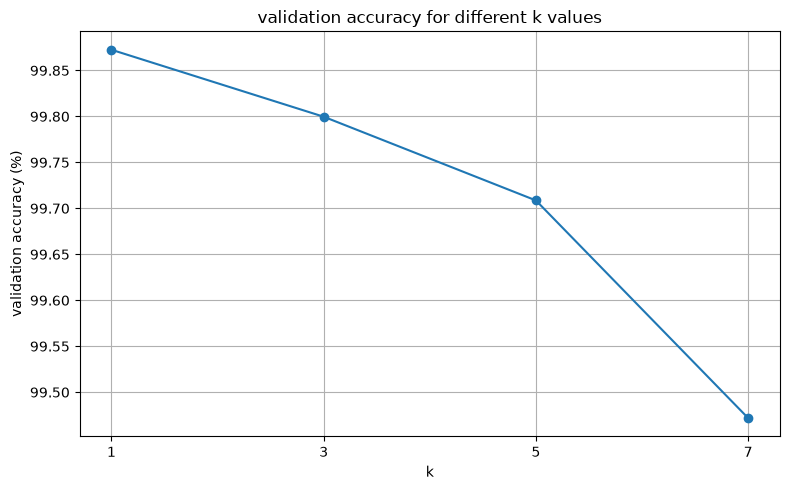

In [16]:
# get the tested k values
k_values_plot = list(knn_results.keys())

# get the accuracy values
accuracy_values = list(knn_results.values())

# convert the accuracy values to percentages
accuracy_percent = [accuracy * 100 for accuracy in accuracy_values]

# create a new figure
plt.figure(figsize=(8, 5))

# draw the accuracy line
plt.plot(k_values_plot, accuracy_percent, marker="o")

# write the k values on the horizontal axis
plt.xticks(k_values_plot)

# write the horizontal axis name
plt.xlabel("k")

# write the vertical axis name
plt.ylabel("validation accuracy (%)")

# write the graph title
plt.title("validation accuracy for different k values")

# add a grid to make the values easier to read
plt.grid(True)

# fix the spacing around the graph
plt.tight_layout()

# save the graph inside the results folder
plt.savefig("../results/figures/knn_k_validation_accuracy.png", dpi=200, bbox_inches="tight")

# show the graph
plt.show()

### conclusion from the k comparison

the graph show that the validation accuracy decreases as k increases.

among the tested values, k = 1 gives the highest validation accuracy.

this tell me that adding more neighbors did not improve the classifier.

maybe spesific for this dataset, the closest single training image is usually more useful
than voting among several nearby images.

therefore, i will keep k = 1 as the best knn model from this experiment.

## experiment 3: linear classifier

### question

how well can a linear classifier separate the hand-sign classes?

### prediction

i expect a linear classifier to achieve high validation accuracy because
the images contain strong visual patterns.

but, i expect it to perform worse than 1-nearest neighbor because a
single linear decision rule may not represent all variations of each hand sign, so i expect the dots sampales
not to be linearley saparable that much

after running the model, i will compare its mistakes with the mistakes made
by 1-nearest neighbor.

## experiment 3: linear classifiers

### why use a linear model?

stage 1 requires a comparison between a local classifier and a linear decision rule.

the local classifier that i already tested is knn.

for the linear part, i will test both logistic regression and linear svm.

### why test logistic regression?

logistic regression is a useful linear baseline.

for each class, it learns a score of the form:

\[
z_c = w_c^T x + b_c
\]

where:

- \(x\) is the image vector
- \(w_c\) is the weight vector for class \(c\)
- \(b_c\) is the bias for class \(c\)
- \(z_c\) is the score for class \(c\)

the model uses these scores to decide which class is the best match.

logistic regression is useful because it is simple, stable, and works naturally
with multiclass classification.

### why also test linear svm?

linear svm is also a linear classifier.

unlike logistic regression, it focuses on finding a decision boundary with a
large margin between classes.

this makes it useful to test whether a different linear learning objective
changes the result.

### why not use linear regression?

linear regression predicts continuous numeric values.

our labels are class identifiers, not meaningful continuous numbers.

for example, the numeric labels 0, 1, and 2 represent different letters.

there is no meaningful numeric distance between these class labels.

because of this, linear regression is not a natural choice for this classification task.

### how are these models different from knn?

knn is a local method.

it predicts a class by looking at nearby training examples.

logistic regression and linear svm are global linear models.

they learn decision boundaries from the full training set instead of searching
for the closest training image.


### prediction

i expect both linear models to achieve high validation accuracy.

but ,i expect 1-nearest neighbor to perform better because it can make
local decisions based on very similar training images.

i do not know if logistic regression or linear svm will perform
better.

testing both will help me understand whether the main limitation comes from
the linear structure itself, or from the specific learning objective.

In [25]:
from sklearn.linear_model import LogisticRegression  # import the logistic regression model

linear_model = LogisticRegression(  # create the linear classifier
    max_iter=10000,  # allow enough training iterations
    solver="lbfgs"  # use the lbfgs optimization method
)  

linear_model.fit(x_train, y_train)  # train the model on the training data

y_val_pred_linear = linear_model.predict(x_val)  # predict the validation labels

linear_accuracy = accuracy_score(y_val, y_val_pred_linear)  # calculate validation accuracy

print("logistic regression validation accuracy:", linear_accuracy)  # print the result

logistic regression validation accuracy: 0.9996357676197414


### logistic regression result
i was wrong

logistic regression achieved a validation accuracy of approximately 99.96%.

the model made only 2 wrong predictions out of 5491 validation images.

this result is better than the 1-nearest neighbor result, which made 7 mistakes.

my prediction that 1-nearest neighbor would perform better was not correct.

this tell me that the hand-sign classes may be highly separable using global
linear decision boundaries in the original pixel space.

but, i still need to inspect the mistakes and compare the result with another
linear classifier before drawing a stronger conclusion.

In [18]:
from sklearn.svm import LinearSVC  # import the linear svm model

# create the linear svm classifier
svm_model = LinearSVC(
    random_state=42,  # make the result reproducible
    max_iter=10000  # allow enough training iterations
)

svm_model.fit(x_train, y_train)  # train the model on the training data

y_val_pred_svm = svm_model.predict(x_val)  # predict the validation labels

svm_accuracy = accuracy_score(y_val, y_val_pred_svm)  # calculate the validation accuracy

print("linear svm validation accuracy:", svm_accuracy)  # print the result

linear svm validation accuracy: 1.0


### linear svm result

linear svm achieved 100% validation accuracy on the current validation split.

it correctly classified all 5491 validation images.

this result is better than both 1-nearest neighbor and logistic regression.

the current comparison is:

- 1-nearest neighbor: 99.87%
- logistic regression: 99.96%
- linear svm: 100%

my original prediction that the local classifier would perform better was not correct.

the result tell me that linear decision boundaries work very good for this dataset.

but, one validation split is not enough to conclude that the data is perfectly
linearly separable or that the model will always achieve 100% accuracy.

in the next step i will check whether this result remains stable when the training
data is split in different ways.because maybe this result is specific to the current split

## validation reliability: linear svm

### question

does linear svm remain highly accurate when the train-validation split changes?

### prediction

i expect linear svm to remain highly accurate across different splits.

however, i do not expect every split to necessarily produce exactly 100% accuracy.

if the results remain very similar across different splits, this will give stronger
evidence that the validation result is reliable.

In [ ]:
# import the train-validation split function
from sklearn.model_selection import train_test_split

# import the linear svm model
from sklearn.svm import LinearSVC

# choose the random seeds to test
seeds = [0, 1, 2, 3, 4]

# create an empty list for the accuracy results
svm_split_results = []

# go through every random seed
for seed in seeds:

    # create a new train-validation split
    x_train_seed, x_val_seed, y_train_seed, y_val_seed = train_test_split(
        x_full,  # use all original training images
        y_full,  # use all original training labels
        test_size=0.2,  # keep twenty percent for validation
        random_state=seed,  # use the current random seed
        stratify=y_full  # keep similar class proportions
    )  

    # convert the training pixels to float values
    x_train_seed = x_train_seed.astype("float32")

    # scale the training pixels to zero-one
    x_train_seed = x_train_seed / 255.0

    # convert the validation pixels to float values
    x_val_seed = x_val_seed.astype("float32")

    # scale the validation pixels to zero-one
    x_val_seed = x_val_seed / 255.0

    # create a new linear svm model
    svm_seed_model = LinearSVC(
        random_state=42,  # keep the model setup reproducible
        max_iter=10000  # allow enough training iterations
    )  

    # train the model on the new training split
    svm_seed_model.fit(x_train_seed, y_train_seed)

    # predict the new validation labels
    y_val_seed_pred = svm_seed_model.predict(x_val_seed)

    # calculate the validation accuracy
    seed_accuracy = accuracy_score(y_val_seed, y_val_seed_pred)

    # save the accuracy result
    svm_split_results.append(seed_accuracy)

    # print the result for this seed
    print("seed =", seed, "accuracy =", seed_accuracy)

seed = 0 accuracy = 0.9998178838098707
seed = 1 accuracy = 0.9998178838098707
seed = 2 accuracy = 0.9998178838098707
seed = 3 accuracy = 1.0
seed = 4 accuracy = 0.9998178838098707


### validation reliability result

linear svm remained very accurate across all five train-validation splits, we obtained from the 5 different seeds.

four splits produced one wrong prediction out of 5491 validation images.

one split produced zero wrong predictions.

the accuracy stayed between approximately 99.98% and 100%.

this tell me that the high linear svm accuracy is not caused by one
particularly easy validation split.

still, the result does not prove that the classes are perfectly linearly
separable, because some of the splits still contained one classification error.

## validation reliability: comparing the three models

### question

does the comparison between the three models remain similar when the
train-validation split changes?

i will compare:

- 1-nearest neighbor
- logistic regression
- linear svm

for several different random seeds.

### prediction

based on the first validation split, i expect all three models to remain
highly accurate.

i expect linear svm to usually achieve the best result, followed by
logistic regression and then 1-nearest neighbor.

however, the exact ranking may change in some splits.

if the results remain similar across different seeds, this will give stronger
evidence that the comparison between the models is reliable.

In [20]:
# import the models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# choose the random seeds
seeds = [0, 1, 2, 3, 4]

# create an empty list for all results
model_split_results = []

# go through every random seed
for seed in seeds:

    # create a new train-validation split
    x_train_seed, x_val_seed, y_train_seed, y_val_seed = train_test_split(
        x_full,  # use all original training images
        y_full,  # use all original training labels
        test_size=0.2,  # use twenty percent for validation
        random_state=seed,  # use the current seed
        stratify=y_full  # keep similar class proportions
    )

    # convert the training pixels to float values
    x_train_seed = x_train_seed.astype("float32")

    # scale the training pixels to zero-one
    x_train_seed = x_train_seed / 255.0

    # convert the validation pixels to float values
    x_val_seed = x_val_seed.astype("float32")

    # scale the validation pixels to zero-one
    x_val_seed = x_val_seed / 255.0

    # create the 1-nearest neighbor model
    knn_seed_model = KNeighborsClassifier(
        n_neighbors=1,  # use one nearest neighbor
        metric="euclidean",  # use euclidean distance
        n_jobs=-1  # use all available cpu cores
    )

    # train the knn model
    knn_seed_model.fit(x_train_seed, y_train_seed)

    # predict with the knn model
    knn_seed_pred = knn_seed_model.predict(x_val_seed)

    # calculate the knn accuracy
    knn_seed_accuracy = accuracy_score(y_val_seed, knn_seed_pred)

    # create the logistic regression model
    logistic_seed_model = LogisticRegression(
        max_iter=2000,  # allow enough training iterations
        solver="lbfgs"  # use the lbfgs optimizer
    )

    # train the logistic regression model
    logistic_seed_model.fit(x_train_seed, y_train_seed)

    # predict with logistic regression
    logistic_seed_pred = logistic_seed_model.predict(x_val_seed)

    # calculate the logistic regression accuracy
    logistic_seed_accuracy = accuracy_score(y_val_seed, logistic_seed_pred)

    # create the linear svm model
    svm_seed_model = LinearSVC(
        random_state=42,  # keep the model reproducible
        max_iter=10000  # allow enough training iterations
    )

    # train the linear svm model
    svm_seed_model.fit(x_train_seed, y_train_seed)

    # predict with the linear svm model
    svm_seed_pred = svm_seed_model.predict(x_val_seed)

    # calculate the linear svm accuracy
    svm_seed_accuracy = accuracy_score(y_val_seed, svm_seed_pred)

    # save all results for this seed
    model_split_results.append(
        {
            "seed": seed,
            "1-nn": knn_seed_accuracy,
            "logistic regression": logistic_seed_accuracy,
            "linear svm": svm_seed_accuracy
        }
    )

    # print the knn result
    print("seed =", seed, "1-nn =", knn_seed_accuracy)

    # print the logistic regression result
    print("seed =", seed, "logistic regression =", logistic_seed_accuracy)

    # print the linear svm result
    print("seed =", seed, "linear svm =", svm_seed_accuracy)

    # print an empty line
    print()

seed = 0 1-nn = 0.9998178838098707
seed = 0 logistic regression = 0.9998178838098707
seed = 0 linear svm = 0.9998178838098707

seed = 1 1-nn = 0.9990894190493534
seed = 1 logistic regression = 0.9996357676197414
seed = 1 linear svm = 0.9998178838098707

seed = 2 1-nn = 0.9994536514296121
seed = 2 logistic regression = 0.9998178838098707
seed = 2 linear svm = 0.9998178838098707

seed = 3 1-nn = 0.9996357676197414
seed = 3 logistic regression = 0.9996357676197414
seed = 3 linear svm = 1.0

seed = 4 1-nn = 0.9994536514296121
seed = 4 logistic regression = 0.9996357676197414
seed = 4 linear svm = 0.9998178838098707



### comparison across different validation splits

the comparison between the three models remained very stable across the five
different train-validation splits.

the average validation accuracies were approximately:

- 1-nearest neighbor: 99.95%
- logistic regression: 99.97%
- linear svm: 99.99%

linear svm achieved the best average result.

logistic regression was slightly worse than linear svm but still performed
better than 1-nearest neighbor on average.

this tell me that the original ranking was not caused by one specific random split.

the results suggest that global linear decision boundaries work very well
for this dataset.

between the tested models, linear svm is the most accurate and the most stable
across the different validation splits.

## error comparison between local and linear models

### question

do 1-nearest neighbor and logistic regression make mistakes on the same
validation images?

### prediction

i expect some of the mistakes to be different.

1-nearest neighbor makes a local decision based on the closest training image.

logistic regression makes a global linear decision based on learned decision
boundaries.

because the two models use different decision rules, they may fail on different
validation images.

In [21]:
# find the wrong 1-nn predictions
knn_wrong_mask = y_val_pred_knn_1 != y_val

# get the positions of the wrong 1-nn predictions
knn_wrong_indices = np.where(knn_wrong_mask)[0]

# find the wrong logistic regression predictions
logistic_wrong_mask = y_val_pred_linear != y_val

# get the positions of the wrong logistic regression predictions
logistic_wrong_indices = np.where(logistic_wrong_mask)[0]

# find the wrong linear svm predictions
svm_wrong_mask = y_val_pred_svm != y_val

# get the positions of the wrong linear svm predictions
svm_wrong_indices = np.where(svm_wrong_mask)[0]

# find mistakes shared by 1-nn and logistic regression
shared_wrong_indices = np.intersect1d(
    knn_wrong_indices,
    logistic_wrong_indices
)

# find mistakes made only by 1-nn
knn_only_wrong = np.setdiff1d(
    knn_wrong_indices,
    logistic_wrong_indices
)

# find mistakes made only by logistic regression
logistic_only_wrong = np.setdiff1d(
    logistic_wrong_indices,
    knn_wrong_indices
)

# print the number of 1-nn mistakes
print("1-nn mistakes:", len(knn_wrong_indices))

# print the number of logistic regression mistakes
print("logistic regression mistakes:", len(logistic_wrong_indices))

# print the number of linear svm mistakes
print("linear svm mistakes:", len(svm_wrong_indices))

# print the shared mistakes
print("shared mistakes:", shared_wrong_indices)

# print mistakes made only by 1-nn
print("1-nn only mistakes:", knn_only_wrong)

# print mistakes made only by logistic regression
print("logistic regression only mistakes:", logistic_only_wrong)

1-nn mistakes: 7
logistic regression mistakes: 2
linear svm mistakes: 0
shared mistakes: []
1-nn only mistakes: [ 296  359  681  988 1655 3857 4977]
logistic regression only mistakes: [ 637 2104]


### error comparison result

1-nearest neighbor made 7 validation mistakes.

logistic regression made 2 validation mistakes.

linear svm made no validation mistakes on this split.

there were no shared mistakes between 1-nearest neighbor and logistic regression.

this tell me that the local and linear classifiers, failed on different validation images.

this supports the idea that the two models use different information when making
their decisions.

1-nearest neighbor depends on the closest local training example, while logistic
regression depends on global linear decision boundaries.

therefore, even though both models achieve very high accuracy, their failure
patterns are different.

## logistic regression error inspection

### question

what do the validation images that logistic regression classified incorrectly look like?

### prediction

because logistic regression made only two mistakes, i expect these examples to be
visually unusual or close to a linear decision boundary.

i also expect these mistakes to be different from the mistakes made by 1-nearest
neighbor, because the two models use different decision rules.

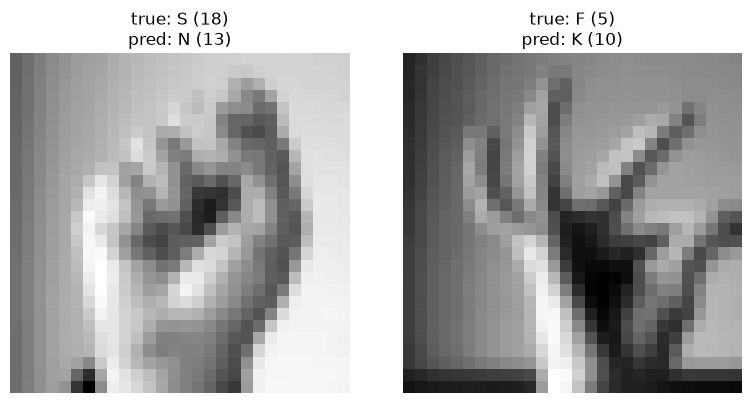

In [22]:
# create a figure for the two wrong images
fig, axes = plt.subplots(1, len(logistic_wrong_indices), figsize=(8, 4))

# go through the wrong logistic regression predictions
for ax, index in zip(axes, logistic_wrong_indices):

    # reshape the image back to 28 by 28 pixels
    image = x_val[index].reshape(28, 28)

    # get the true numeric label
    true_label = int(y_val[index])

    # get the predicted numeric label
    predicted_label = int(y_val_pred_linear[index])

    # convert the true label to a letter
    true_letter = chr(ord("A") + true_label)

    # convert the predicted label to a letter
    predicted_letter = chr(ord("A") + predicted_label)

    # show the image
    ax.imshow(image, cmap="gray")

    # show the true and predicted labels
    ax.set_title(
        f"true: {true_letter} ({true_label})\npred: {predicted_letter} ({predicted_label})"
    )

    # hide the axes
    ax.axis("off")

# fix the spacing
plt.tight_layout()

# show the figure
plt.show()

### logistic regression error inspection result

logistic regression made two mistakes on the current validation split.

the mistakes were:

- S was predicted as N
- F was predicted as K

these images are different from all seven images that were misclassified by
1-nearest neighbor.

this support the idea that the local and linear classifiers fail in different
situations.

the images alone do not tell me whether these examples are close to a linear
decision boundary.

to check that, i need to examine the model scores for the true and predicted
classes.

## logistic regression confidence on wrong predictions

### question

how confident was logistic regression when it made its two wrong predictions?

### prediction

i expect the predicted class and the true class to have relatively close scores.

if the two highest scores are close, this will tell me that the model was uncertain
between two classes.

if the difference is large, this means that the model made a confident mistake.

In [23]:
# get the model scores for the wrong images
wrong_scores = linear_model.decision_function(x_val[logistic_wrong_indices])

# go through every wrong image
for row, index in enumerate(logistic_wrong_indices):

    # get the scores for this image
    scores = wrong_scores[row]

    # sort the score positions from highest to lowest
    sorted_positions = np.argsort(scores)[::-1]

    # get the position of the highest score
    first_position = sorted_positions[0]

    # get the position of the second highest score
    second_position = sorted_positions[1]

    # get the label of the highest score
    first_label = int(linear_model.classes_[first_position])

    # get the label of the second highest score
    second_label = int(linear_model.classes_[second_position])

    # get the highest score
    first_score = scores[first_position]

    # get the second highest score
    second_score = scores[second_position]

    # calculate the difference between the two highest scores
    score_gap = first_score - second_score

    # get the true label
    true_label = int(y_val[index])

    # convert the true label to a letter
    true_letter = chr(ord("A") + true_label)

    # convert the highest score label to a letter
    first_letter = chr(ord("A") + first_label)

    # convert the second score label to a letter
    second_letter = chr(ord("A") + second_label)

    # print the true class
    print("true:", true_letter, true_label)

    # print the class with the highest score
    print("highest score:", first_letter, first_label, first_score)

    # print the class with the second highest score
    print("second score:", second_letter, second_label, second_score)

    # print the difference between the two highest scores
    print("score gap:", score_gap)

    # print an empty line
    print()

true: S 18
highest score: N 13 10.545474
second score: S 18 10.476743
score gap: 0.06873131

true: F 5
highest score: K 10 7.683128
second score: F 5 7.5174346
score gap: 0.16569328



### logistic regression confidence result

for both wrong predictions, the true class had the second highest model score.

for the S image, the model predicted N, but the score difference between N and S
was only about 0.069.

for the F image, the model predicted K, but the score difference between K and F
was only about 0.166.

this shows that the true class was still a strong candidate in both cases.

the model did not strongly reject the true class. instead, another class received
a slightly higher score.

but, i still need to compare these score gaps with the gaps of correctly
classified images before concluding that these values are unusually small.

In [24]:
# get the model scores for all validation images
all_scores = linear_model.decision_function(x_val)

# sort the scores in each row
sorted_scores = np.sort(all_scores, axis=1)

# get the highest score for each image
highest_scores = sorted_scores[:, -1]

# get the second highest score for each image
second_scores = sorted_scores[:, -2]

# calculate the top-two score gap for each image
all_score_gaps = highest_scores - second_scores

# get the gaps for correct predictions
correct_gaps = all_score_gaps[y_val_pred_linear == y_val]

# get the gaps for wrong predictions
wrong_gaps = all_score_gaps[y_val_pred_linear != y_val]

# print the average gap for correct predictions
print("mean correct gap:", correct_gaps.mean())

# print the median gap for correct predictions
print("median correct gap:", np.median(correct_gaps))

# print the smallest gap for correct predictions
print("minimum correct gap:", correct_gaps.min())

# print the gaps for the wrong predictions
print("wrong prediction gaps:", wrong_gaps)

mean correct gap: 4.4749436
median correct gap: 4.0873866
minimum correct gap: 0.11314297
wrong prediction gaps: [0.06875515 0.1656928 ]


### score gap analysis for logistic regression mistakes

i compared the score gaps of the wrong predictions with the score gaps of all
correct predictions.

the two wrong predictions had score gaps:

- 0.0688
- 0.1657

for the correctly classified validation images, the score gaps were much larger
in general:

- mean correct gap: 4.4749
- median correct gap: 4.0874
- minimum correct gap: 0.1131

this tell me that both wrong predictions were made with unusually small score gaps.

one wrong example had a gap even smaller than the minimum gap among all correct
predictions, and the other was still very small compared with the typical
correct gap.

this supports the conclusion that the logistic regression mistakes happened on
ambiguous images that were close to a decision boundary between similar classes.

## stage 1 model comparison sum up

 i compared one local classifier and two linear classifiers:

- 1-nearest neighbor
- logistic regression
- linear svm

### validation accuracy

on the original validation split:

- 1-nearest neighbor achieved about 99.87% accuracy
- logistic regression achieved about 99.96% accuracy
- linear svm achieved 100% accuracy

the linear models therefore performed slightly better than the local classifier.

### validation reliability

i repeated the comparison using five different train-validation splits.

all three models remained highly accurate across the different random seeds.

the average results were approximately:

- 1-nearest neighbor: 99.95%
- logistic regression: 99.97%
- linear svm: 99.99%

linear svm was the strongest and most stable model among the tested classifiers.

### error behavior

1-nearest neighbor and logistic regression did not make mistakes on the same
validation images.

1-nearest neighbor made 7 mistakes on the original split, while logistic
regression made 2 mistakes.

the shared mistake set was empty.

this shows that the local and linear classifiers can fail in different situations.

### what caused the local errors?

1-nearest neighbor failed mainly when a validation image was visually close to
a training image from another class.

examples included confusions such as:

- V with W
- V with U
- R with U
- M with N

this shows that pixel-space distance can confuse different letters that have
similar hand shapes.

### what caused the linear errors?

logistic regression made two mistakes:

- S was predicted as N
- F was predicted as K

in both cases, the true class had the second highest model score.

the score gaps were very small:

- 0.0688
- 0.1657

for comparison, the mean score gap for correctly classified images was about
4.47 and the median was about 4.09.

this suggests that the logistic regression mistakes happened on ambiguous
examples close to a linear decision boundary.

### final conclusion

the experiments show that pixel geometry contains very strong information about
the hand-sign classes.

the local classifier performs very well, but it can fail when a nearby
training image belongs to a visually similar class.

the linear classifiers perform even better on this dataset.

their errors are different from the local classifier errors, which shows that
the local and linear decision rules fail in different ways.

between the tested models, linear svm currently gives the best and most stable
validation performance.